<a href="https://colab.research.google.com/github/YeweonJung/workshop/blob/main/%EB%AA%A8%EB%8D%B8%EC%A7%84%EB%8B%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 모델 진단과 Effect Size


## 1. 비선형 관계: 직선 vs 곡선

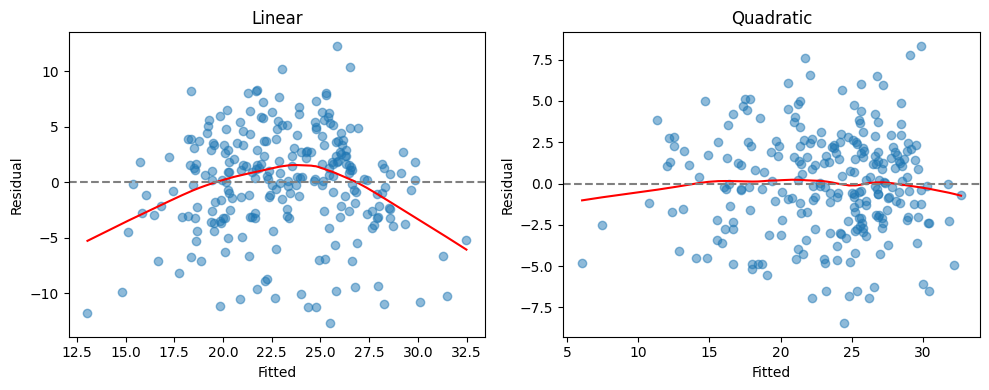

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy import stats
from IPython.display import display

rng = np.random.default_rng(42)
n = 250
dose = rng.uniform(0, 10, n)
age = rng.normal(40, 8, n)
y = 10 + 6*dose - 0.5*dose**2 + 0.3*(age-40) + rng.normal(0, 3, n)
X = pd.DataFrame({'Intercept': 1, 'Dose': dose, 'Age': age-40})
X2 = X.assign(Dose2=dose**2)
linear = sm.OLS(y, X).fit()
quadratic = sm.OLS(y, X2).fit()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model, title in zip(axes, [linear, quadratic], ['Linear', 'Quadratic']):
    ax.scatter(model.fittedvalues, model.resid, alpha=0.5)
    smooth = lowess(model.resid, model.fittedvalues)
    ax.plot(smooth[:, 0], smooth[:, 1], color='red')
    ax.axhline(0, color='gray', linestyle='--')
    ax.set(xlabel='Fitted', ylabel='Residual', title=title)
plt.tight_layout()
plt.show()

## 2. Q–Q plot · Observed vs Fitted


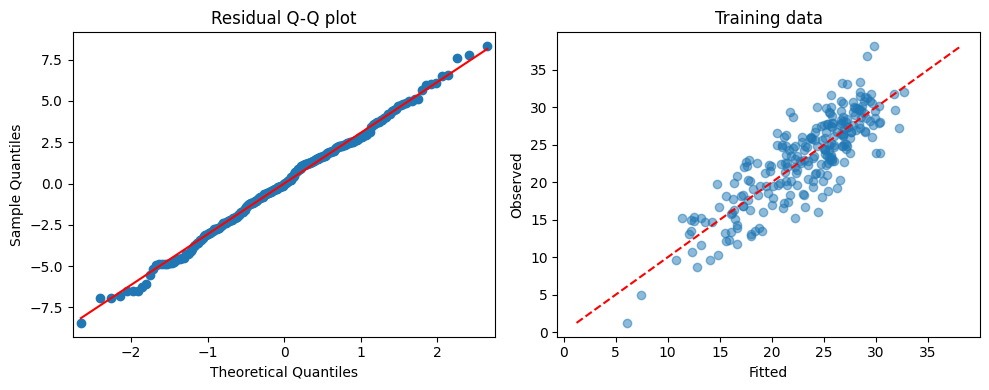

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sm.qqplot(quadratic.resid, line='s', ax=axes[0])
axes[0].set_title('Residual Q-Q plot')
axes[1].scatter(quadratic.fittedvalues, y, alpha=0.5)
limits = [min(y.min(), quadratic.fittedvalues.min()), max(y.max(), quadratic.fittedvalues.max())]
axes[1].plot(limits, limits, 'r--')
axes[1].set(xlabel='Fitted', ylabel='Observed', title='Training data')
plt.tight_layout()
plt.show()

## 3. 이분산성: 검정과 HC3 표준오차


Breusch-Pagan p: 1.347035672424506e-10
White p: 6.943718863291329e-10


,Method,Slope,SE,Lower 95%,Upper 95%,p
0,OLS,2.190482,0.173368,1.849021,2.531943,1.389299e-28
1,HC3,2.190482,0.182565,1.830905,2.550059,1.857201e-26


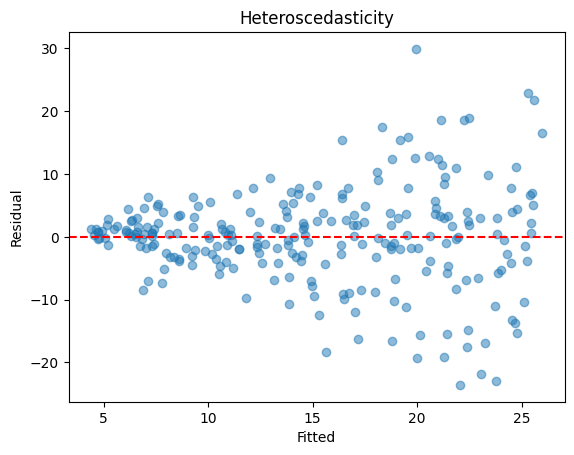

In [ ]:
sigma = 1 + 1.2*dose
y_hetero = 5 + 2*dose + rng.normal(0, sigma)
H = sm.add_constant(dose)
ols = sm.OLS(y_hetero, H).fit()
hc3 = ols.get_robustcov_results(cov_type='HC3')
print('Breusch-Pagan p:', het_breuschpagan(ols.resid, H)[1])
print('White p:', het_white(ols.resid, H)[1])
rows = []
for name, model in [('OLS', ols), ('HC3', hc3)]:
    rows.append([name, model.params[1], model.bse[1], *model.conf_int()[1], model.pvalues[1]])
display(pd.DataFrame(rows, columns=['Method', 'Slope', 'SE', 'Lower 95%', 'Upper 95%', 'p']))
plt.scatter(ols.fittedvalues, ols.resid, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted')
plt.ylabel('Residual')
plt.title('Heteroscedasticity')
plt.show()

## 4. Cook’s distance · Leverage · 민감도 분석

검토 대상 행 번호: 80 | Cook: 11.756 | Leverage: 0.275
전체 기울기: 2.601 | 해당 점 제외: 1.912


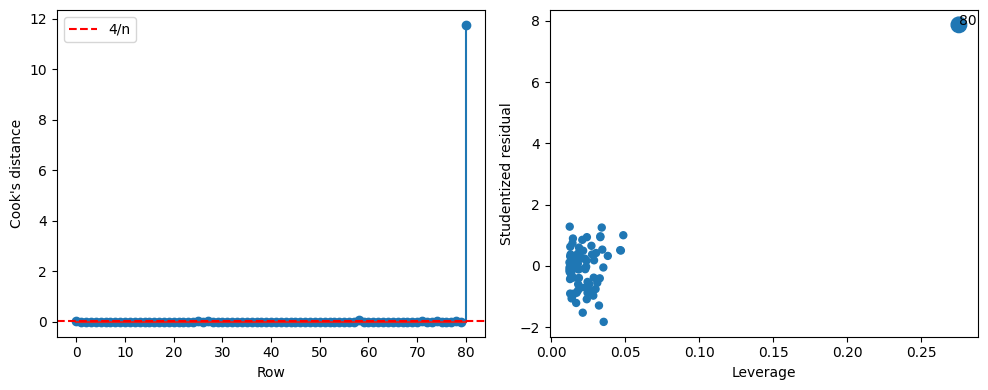

In [ ]:
x = np.r_[rng.uniform(0, 10, 80), 20]
outcome = 5 + 2*x + rng.normal(0, 2, len(x))
outcome[-1] += 35  # 0으로 바꾸면 높은 leverage만 남는지 확인
full = sm.OLS(outcome, sm.add_constant(x)).fit()
influence = full.get_influence()
cook = influence.cooks_distance[0]
leverage = influence.hat_matrix_diag
i = int(np.argmax(cook))
keep = np.arange(len(x)) != i
sensitivity = sm.OLS(outcome[keep], sm.add_constant(x[keep])).fit()
print('검토 대상 행 번호:', i, '| Cook:', round(cook[i], 3), '| Leverage:', round(leverage[i], 3))
print('전체 기울기:', round(full.params[1], 3), '| 해당 점 제외:', round(sensitivity.params[1], 3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].stem(np.arange(len(x)), cook)
axes[0].axhline(4/len(x), color='red', linestyle='--', label='4/n')
axes[0].set(xlabel='Row', ylabel="Cook's distance")
axes[0].legend()
axes[1].scatter(leverage, influence.resid_studentized_internal, s=25+100*cook/cook.max())
axes[1].annotate(str(i), (leverage[i], influence.resid_studentized_internal[i]))
axes[1].set(xlabel='Leverage', ylabel='Studentized residual')
plt.tight_layout()
plt.show()

## 5. 부분 잔차: Dose의 곡선 패턴
부분 잔차 = 잔차 + Dose 계수 × Dose

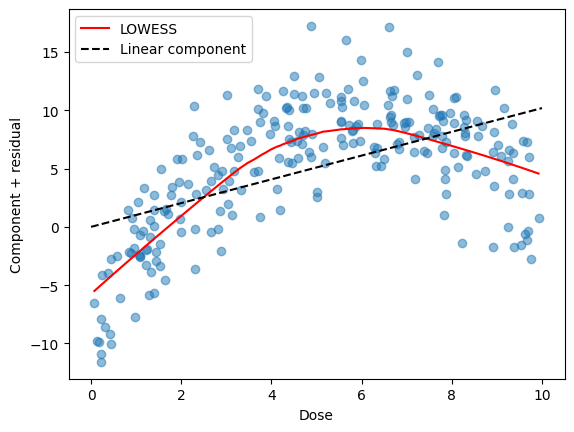

In [ ]:
partial = linear.resid + linear.params['Dose']*dose
plt.scatter(dose, partial, alpha=0.5)
smooth = lowess(partial, dose)
plt.plot(smooth[:, 0], smooth[:, 1], color='red', label='LOWESS')
xx = np.linspace(0, 10, 100)
plt.plot(xx, linear.params['Dose']*xx, 'k--', label='Linear component')
plt.xlabel('Dose')
plt.ylabel('Component + residual')
plt.legend()
plt.show()

## 6. 보정된 평균 차이 + 95% CI


Adjusted difference, 95% CI, p:
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             4.9234      1.053      4.677      0.000       2.852       6.995


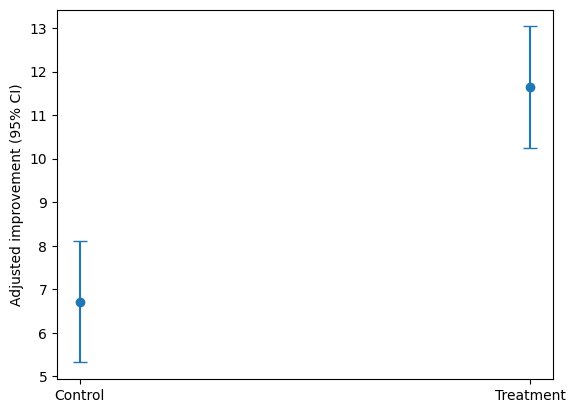

In [ ]:
rng = np.random.default_rng(9)
treatment = np.repeat([0, 1], 150)
baseline = rng.normal(60 + 10*treatment, 10)
improvement = 5 + 4*treatment + 0.4*(baseline-60) + rng.normal(0, 8, 300)
A = pd.DataFrame({'Intercept': 1, 'Treatment': treatment, 'Baseline': baseline-baseline.mean()})
ancova = sm.OLS(improvement, A).fit()
grid = np.array([[1, 0, 0], [1, 1, 0]])
pred = ancova.get_prediction(grid).summary_frame()
contrast = ancova.t_test(grid[1]-grid[0])
print('Adjusted difference, 95% CI, p:')
print(contrast)
plt.errorbar(['Control', 'Treatment'], pred['mean'].to_numpy(),
             yerr=np.array([pred['mean']-pred.mean_ci_lower, pred.mean_ci_upper-pred['mean']]),
             fmt='o', capsize=5)
plt.ylabel('Adjusted improvement (95% CI)')
plt.show()

## 7. Cohen’s d · η² · Partial η²
Cohen’s d와 일원분산분석 η²는 비보정 값

In [ ]:
a = improvement[treatment == 1]
b = improvement[treatment == 0]
pooled_sd = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
d = (a.mean()-b.mean())/pooled_sd
oneway = sm.OLS(improvement, A[['Intercept', 'Treatment']]).fit()
ss_total = np.sum((improvement-improvement.mean())**2)
eta2 = (ss_total-oneway.ssr)/ss_total
reduced = sm.OLS(improvement, A[['Intercept', 'Baseline']]).fit()
ss_treatment = reduced.ssr - ancova.ssr
partial_eta2 = ss_treatment/(ss_treatment+ancova.ssr)
display(pd.Series({'Raw mean difference': a.mean()-b.mean(),
                   "Cohen's d (unadjusted)": d,
                   'Eta-squared (one-way)': eta2,
                   'Partial eta-squared (ANCOVA treatment)': partial_eta2}))

,0
Raw mean difference,8.402490
Cohen's d (unadjusted),0.928064
Eta-squared (one-way),0.178153
Partial eta-squared (ANCOVA treatment),0.068608


## 8. 작은 효과도 표본이 크면 유의할 수 있음


,n per group,Difference,Lower,Upper,d,p
0,30,1,-4.168412,6.168412,0.1,0.699953
1,300,1,-0.603549,2.603549,0.1,0.221154
2,3000,1,0.493837,1.506163,0.1,0.000109


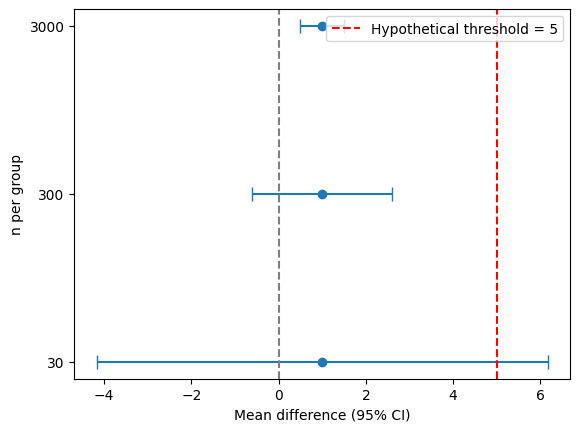

In [ ]:
rows = []
for n in [30, 300, 3000]:
    difference, sd = 1, 10
    se = sd*np.sqrt(2/n)
    margin = stats.t.ppf(0.975, 2*n-2)*se
    p = 2*stats.t.sf(abs(difference/se), 2*n-2)
    rows.append([n, difference, difference-margin, difference+margin, difference/sd, p])
size = pd.DataFrame(rows, columns=['n per group', 'Difference', 'Lower', 'Upper', 'd', 'p'])
display(size)
plt.errorbar(size.Difference.to_numpy(), size['n per group'].astype(str),
             xerr=np.array([size.Difference-size.Lower, size.Upper-size.Difference]), fmt='o', capsize=5)
plt.axvline(0, color='gray', linestyle='--')
plt.axvline(5, color='red', linestyle='--', label='Hypothetical threshold = 5')
plt.xlabel('Mean difference (95% CI)')
plt.ylabel('n per group')
plt.legend()
plt.show()